# Tianeptine – OGD bulk RNA-seq: QC and PCA

**Data:** GEO GSE234798 (Ersoy et al., 2024) – primary mouse cortical neurons, 2×2 design (OGD/control × tianeptine/vehicle), 4 biological replicates per group.

**Aim:** Explore the dataset, perform quality control, and assess sample similarity using principal component analysis (PCA).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.decomposition import PCA

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.1.0
numpy: 2.5.4


## 1. Load the data

In [2]:
counts = pd.read_csv("../data/isoforms.matrix.counts.csv", sep="\t")
counts.shape

(135276, 25)

In [3]:
counts.head()

,Ensembl Id,EntrezGene,Gene Symbol,Description,Chromosome,Strand,Band,Transcript_start,Transcript_end,X1,...,X15,X16,X2,X3,X4,X5,X6,X7,X8,X9
0,ENSMUST00000146893,56440.0,Snx1,sorting nexin 1,9,-1.0,C,66104475.0,66105724.0,48.618125,...,0.000000,53.392223,4.190639,19.820981,49.928951,7.025128,8.300586,8.603677,20.596287,19.933761
1,ENSMUST00000182056,545192.0,Baiap3,BAI1-associated protein 3,17,-1.0,A3.3,25242659.0,25256364.0,107.406169,...,40.993206,43.483726,108.234234,84.689087,87.313166,117.655350,75.466879,80.520198,111.233696,46.569647
2,ENSMUST00000176712,240095.0,H2-M5,"histocompatibility 2, M region locus 5",17,-1.0,B1,36987115.0,36989188.0,0.000000,...,0.000363,0.005719,0.000144,0.000000,0.000000,0.000900,0.000000,0.000000,0.000000,0.000000
3,ENSMUST00000228469,NaN,Gm2611,predicted gene 2611,15,-1.0,A2,16599958.0,16600562.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,ENSMUST00000123080,20448.0,St6galnac4,"ST6 (alpha-N-acetyl-neuraminyl-2,3-beta-galact...",2,1.0,B,32587139.0,32594275.0,301.483437,...,223.703572,254.629912,280.480507,322.875194,144.875944,264.801405,332.345332,311.274274,307.882932,129.971083


In [4]:
metadata = pd.read_csv("../data/metadata.csv")
metadata

,sample,geo_accession,group,condition,treatment
0,X1,GSM7474909,CONTROL-VEH,CONTROL,VEH
1,X2,GSM7474910,CONTROL-VEH,CONTROL,VEH
2,X3,GSM7474911,CONTROL-VEH,CONTROL,VEH
3,X4,GSM7474912,CONTROL-VEH,CONTROL,VEH
4,X5,GSM7474913,CONTROL-TIA,CONTROL,TIA
5,X6,GSM7474914,CONTROL-TIA,CONTROL,TIA
6,X7,GSM7474915,CONTROL-TIA,CONTROL,TIA
7,X8,GSM7474916,CONTROL-TIA,CONTROL,TIA
8,X9,GSM7474917,OGD-VEH,OGD,VEH
9,X10,GSM7474918,OGD-VEH,OGD,VEH


In [5]:
samples = metadata["sample"].tolist()
print(samples)

['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16']


In [6]:
counts[samples].head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16
0,48.618125,4.190639,19.820981,49.928951,7.025128,8.300586,8.603677,20.596287,19.933761,32.328251,14.452120,43.081885,0.000000,22.422070,0.000000,53.392223
1,107.406169,108.234234,84.689087,87.313166,117.655350,75.466879,80.520198,111.233696,46.569647,34.307203,26.933794,28.049616,54.554527,49.871471,40.993206,43.483726
2,0.000000,0.000144,0.000000,0.000000,0.000900,0.000000,0.000000,0.000000,0.000000,0.000000,0.000005,0.000000,0.000000,0.000000,0.000363,0.005719
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,301.483437,280.480507,322.875194,144.875944,264.801405,332.345332,311.274274,307.882932,129.971083,153.362471,199.021159,238.445730,170.857816,267.889073,223.703572,254.629912


## 2. Aggregate transcripts to gene-level counts

Counts are provided at transcript (isoform) level. For differential expression analysis, read counts of all isoforms of a gene are summed to obtain gene-level counts.

In [7]:
gene_counts = counts.groupby("Gene Symbol")[samples].sum()
gene_counts.shape

(53679, 16)

In [8]:
gene_counts.loc["Snx1"]

X1     1299.928576
X2     1057.945618
X3     1273.830872
X4     1411.189120
X5     1280.877365
X6     1257.035453
X7     1149.287527
X8     1376.211734
X9     1206.726023
X10    1847.564797
X11    1617.269924
X12    2260.239438
X13    1563.241269
X14    1469.891814
X15    1433.876703
X16    1781.389527
Name: Snx1, dtype: float64

In [9]:
library_size = gene_counts.sum()
library_size

X1     3.935228e+07
X2     3.385364e+07
X3     4.206248e+07
X4     3.794687e+07
X5     4.157056e+07
X6     3.868145e+07
X7     3.696950e+07
X8     4.152998e+07
X9     3.280018e+07
X10    3.803012e+07
X11    3.674990e+07
X12    3.747314e+07
X13    4.111104e+07
X14    4.268215e+07
X15    4.091782e+07
X16    3.797996e+07
dtype: float64

## 3. Quality control

### 3.1 Library size

Total number of reads assigned to genes in each sample. Large differences between samples could indicate technical problems (e.g. failed library preparation).

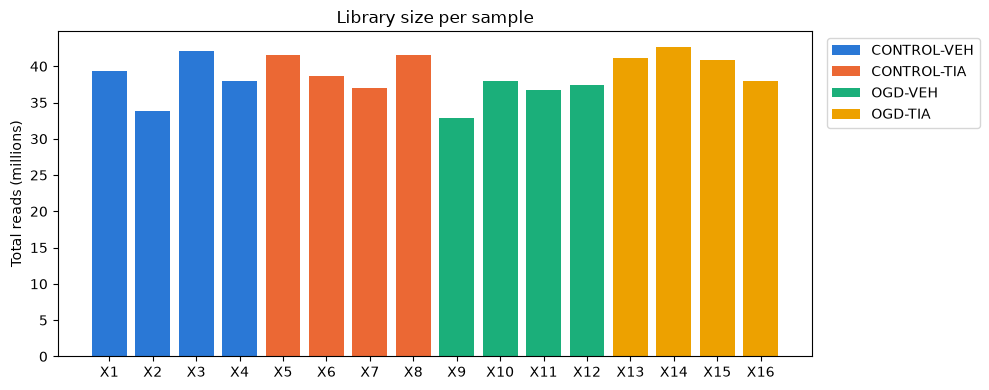

In [10]:
group_colors = {
    "CONTROL-VEH": "#2a78d6",
    "CONTROL-TIA": "#eb6834",
    "OGD-VEH": "#1baf7a",
    "OGD-TIA": "#eda100",
}

fig, ax = plt.subplots(figsize=(10, 4))

for group, color in group_colors.items():
    group_samples = metadata.loc[metadata["group"] == group, "sample"]
    ax.bar(group_samples, library_size[group_samples] / 1e6, color=color, label=group)

ax.set_ylabel("Total reads (millions)")
ax.set_title("Library size per sample")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

**Observation:** All samples have 33–43 million reads (max/min ratio ≈ 1.3). Library sizes are comparable across all four groups, with no failed or outlier library. Note: X9 has the lowest depth (32.8 M), but this is within the normal range and cannot explain its unusual expression profile (see PCA).

### 3.2 Filter lowly expressed genes

Genes with very low counts carry little information and reduce statistical power. Genes are kept if they have at least 10 reads in at least 4 samples (the size of the smallest group). *Note:* This threshold is a trade-off. Genes with consistent but low expression in a single group (e.g. 9–19 reads) may be removed. Among the removed genes, 339 have a group mean above 10 reads; most are poorly characterised RIKEN genes with noisy, low counts. DESeq2's independent filtering is applied in addition during testing.

In [11]:
keep = (gene_counts >= 10).sum(axis=1) >= 4
filtered_counts = gene_counts[keep]

print("Genes before filtering:", gene_counts.shape[0])
print("Genes after filtering: ", filtered_counts.shape[0])

Genes before filtering: 53679
Genes after filtering:  18665


### 3.3 Normalisation and log transformation

Raw counts are normalised to counts per million (CPM) to correct for differences in sequencing depth, then log2-transformed (with a pseudocount of 1) so that highly expressed genes do not dominate and differences reflect fold changes. These log-CPM values are used for exploratory analyses (correlation, PCA). Differential expression will be performed on raw counts with DESeq2, which applies its own normalisation.

In [12]:
cpm = filtered_counts / filtered_counts.sum() * 1e6
log_cpm = np.log2(cpm + 1)

log_cpm.loc["Snx1", ["X1", "X12"]]

X1     5.089732
X12    5.939062
Name: Snx1, dtype: float64

**Effect of the log transformation.** Distribution of expression values in one sample (X1) before and after log transformation.

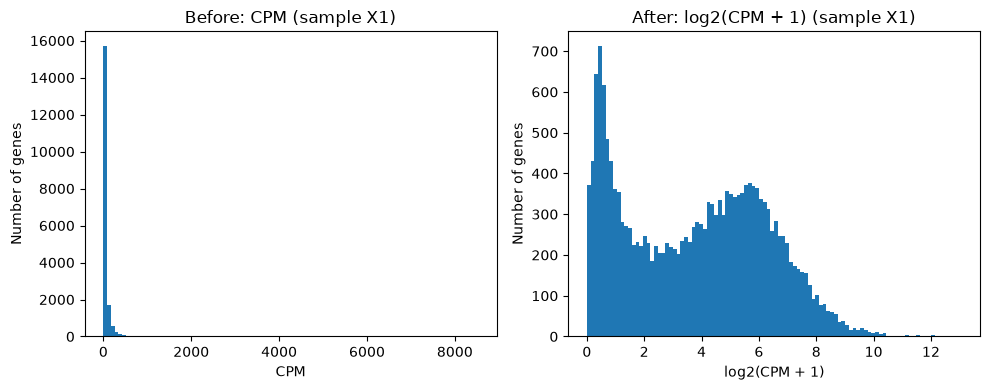

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(cpm["X1"], bins=100)
axes[0].set_xlabel("CPM")
axes[0].set_ylabel("Number of genes")
axes[0].set_title("Before: CPM (sample X1)")

axes[1].hist(log_cpm["X1"], bins=100)
axes[1].set_xlabel("log2(CPM + 1)")
axes[1].set_ylabel("Number of genes")
axes[1].set_title("After: log2(CPM + 1) (sample X1)")

fig.tight_layout()
plt.show()

**Distribution per sample.** Boxplots of log2(CPM + 1) values for all 16 samples. Similar distributions indicate that normalisation worked and that no sample is a technical outlier.

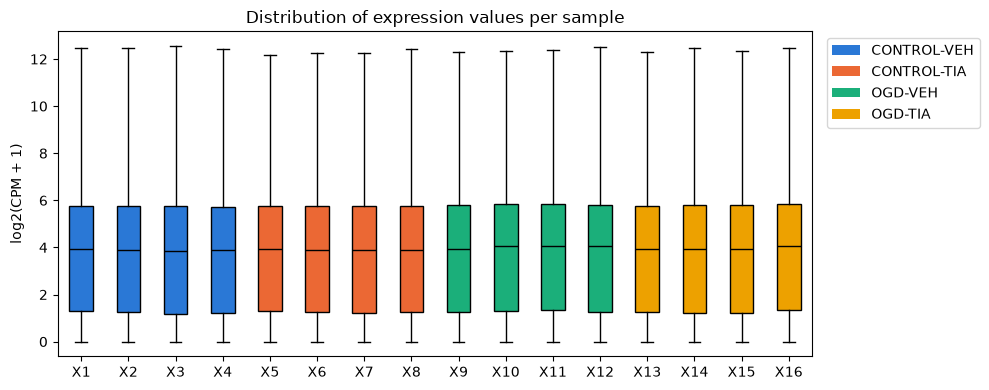

In [14]:
sample_colors = metadata["group"].map(group_colors)

fig, ax = plt.subplots(figsize=(10, 4))
bp = ax.boxplot(log_cpm.values, tick_labels=samples, patch_artist=True,
                showfliers=False, medianprops={"color": "black"})

for box, color in zip(bp["boxes"], sample_colors):
    box.set_facecolor(color)

handles = []
for group, color in group_colors.items():
    handles.append(Patch(facecolor=color, label=group))

ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_ylabel("log2(CPM + 1)")
ax.set_title("Distribution of expression values per sample")
fig.tight_layout()
plt.show()

**Observation:** The distributions are nearly identical across all 16 samples (median log2(CPM + 1) ≈ 4, i.e. ~15 CPM for a typical gene), indicating successful normalisation and no technical outlier.

In [15]:
log_cpm.median().round(2)

X1     3.92
X2     3.88
X3     3.85
X4     3.90
X5     3.93
X6     3.90
X7     3.87
X8     3.89
X9     3.94
X10    4.04
X11    4.04
X12    4.05
X13    3.93
X14    3.93
X15    3.91
X16    4.08
dtype: float64

### 3.4 Sample-to-sample correlation

Pearson correlation between samples, computed on log2(CPM + 1) values of all filtered genes. Samples from the same group are expected to correlate more strongly with each other than with samples from other groups.

In [16]:
corr = log_cpm.corr()
corr.round(3)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16
X1,1.000,0.994,0.994,0.987,0.996,0.995,0.994,0.994,0.992,0.975,0.978,0.951,0.992,0.992,0.992,0.975
X2,0.994,1.000,0.994,0.987,0.994,0.995,0.995,0.994,0.991,0.973,0.976,0.948,0.991,0.991,0.992,0.973
X3,0.994,0.994,1.000,0.988,0.994,0.995,0.995,0.994,0.992,0.975,0.978,0.952,0.992,0.992,0.993,0.975
X4,0.987,0.987,0.988,1.000,0.988,0.988,0.988,0.989,0.987,0.973,0.975,0.956,0.987,0.987,0.986,0.977
X5,0.996,0.994,0.994,0.988,1.000,0.995,0.994,0.994,0.992,0.976,0.979,0.953,0.992,0.992,0.992,0.976
X6,0.995,0.995,0.995,0.988,0.995,1.000,0.995,0.995,0.992,0.975,0.978,0.950,0.992,0.992,0.993,0.975
X7,0.994,0.995,0.995,0.988,0.994,0.995,1.000,0.994,0.992,0.975,0.978,0.950,0.992,0.992,0.993,0.975
X8,0.994,0.994,0.994,0.989,0.994,0.995,0.994,1.000,0.991,0.973,0.976,0.950,0.991,0.991,0.991,0.975
X9,0.992,0.991,0.992,0.987,0.992,0.992,0.992,0.991,1.000,0.985,0.987,0.965,0.995,0.995,0.994,0.984
X10,0.975,0.973,0.975,0.973,0.976,0.975,0.975,0.973,0.985,1.000,0.995,0.986,0.983,0.987,0.984,0.993


In [17]:
print("seaborn:", sns.__version__)

seaborn: 0.13.2


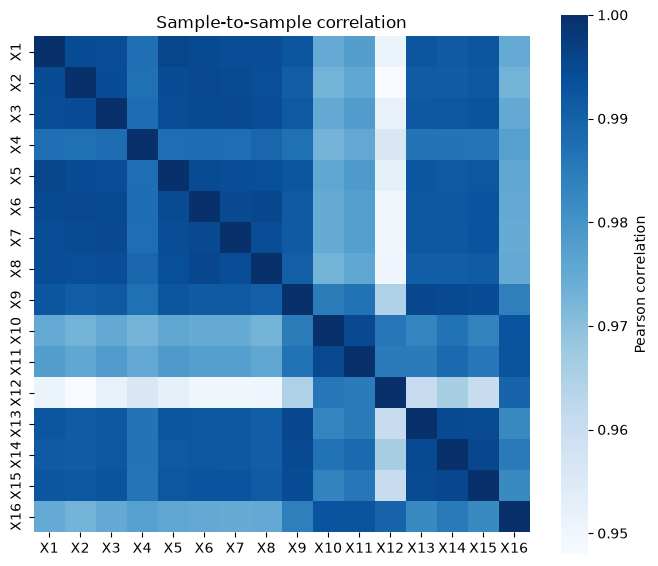

In [18]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr, cmap="Blues", square=True, ax=ax, cbar_kws={"label": "Pearson correlation"})
ax.set_title("Sample-to-sample correlation")
plt.show()

**Observation:** All samples are highly correlated (r > 0.94). Control samples (X1–X8) form a tight cluster together with X9, X13, X14 and X15. Samples X10, X11, X12 and X16 are less correlated with controls (r ≈ 0.95–0.98) but correlate well with each other, indicating a stronger transcriptional response to OGD. X12 is the most distinct sample. X4 is slightly less correlated with the other controls.

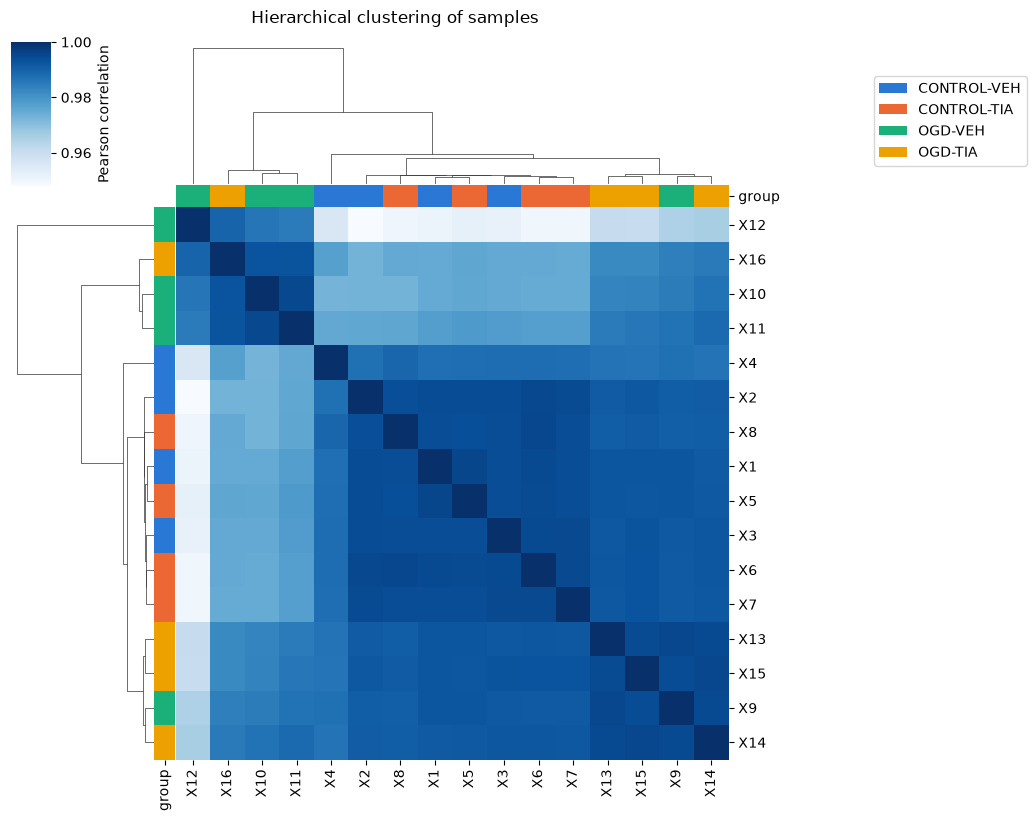

In [19]:
sample_group_colors = metadata.set_index("sample")["group"].map(group_colors)
cg = sns.clustermap(corr, cmap="Blues", row_colors=sample_group_colors, col_colors=sample_group_colors,
                    figsize=(8, 8), cbar_kws={"label": "Pearson correlation"})
cg.ax_heatmap.legend(handles=handles, bbox_to_anchor=(1.25, 1.25), loc="upper left")
cg.figure.suptitle("Hierarchical clustering of samples", y=1.02)
plt.show()

**Observation:** Unsupervised hierarchical clustering (without group labels) separates samples primarily by the strength of the OGD response rather than by group label. The first split separates X10, X11, X12 and X16 ("strong OGD response") from all other samples. CONTROL-VEH and CONTROL-TIA samples are intermixed, suggesting that tianeptine alone has little effect on the transcriptome under normoxic conditions. Three of four OGD-TIA samples (X13–X15) cluster close to controls, consistent with a protective effect of tianeptine; X9 (OGD-VEH) clusters with them, whereas X16 (OGD-TIA) clusters with the strong responders.

### 3.5 Principal component analysis (PCA)

PCA reduces the high-dimensional expression data to a few axes (principal components) that capture the largest sources of variation between samples. Following the DESeq2 convention, the 500 genes with the highest variance across samples are used.

In [20]:
gene_variance = log_cpm.var(axis=1)
top_genes = gene_variance.sort_values(ascending=False).head(500).index
len(top_genes)

500

In [21]:
pca_input = log_cpm.loc[top_genes].T
pca_input.shape

(16, 500)

In [22]:
pca = PCA(n_components=4)
pcs = pca.fit_transform(pca_input)
pca_df = pd.DataFrame(pcs, index=pca_input.index, columns=["PC1", "PC2", "PC3", "PC4"])
pca_df.round(2)

,PC1,PC2,PC3,PC4
X1,-11.41,1.93,2.36,-8.43
X2,-14.33,1.95,-1.72,-0.48
X3,-11.61,-1.17,2.31,2.03
X4,-9.45,-16.35,-5.78,1.69
X5,-9.33,0.93,-4.95,-8.53
X6,-12.45,1.92,3.54,0.16
X7,-13.17,1.60,0.90,8.02
X8,-12.17,-1.82,9.23,0.23
X9,-0.10,1.09,-0.28,0.83
X10,22.01,4.79,-3.60,1.92


In [23]:
explained = pca.explained_variance_ratio_ * 100
explained.round(1)

array([59.6,  6.9,  3.9,  3.9])

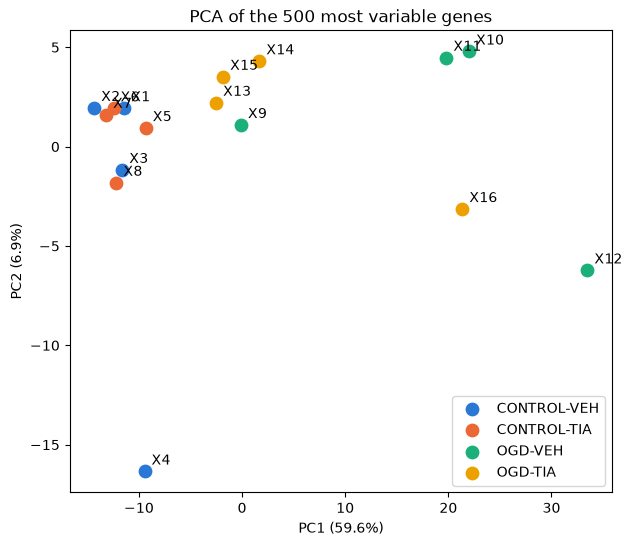

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))

for group, color in group_colors.items():
    group_samples = metadata.loc[metadata["group"] == group, "sample"]
    ax.scatter(pca_df.loc[group_samples, "PC1"], pca_df.loc[group_samples, "PC2"],
               color=color, label=group, s=80)

for sample in pca_df.index:
    ax.annotate(sample, (pca_df.loc[sample, "PC1"], pca_df.loc[sample, "PC2"]),
                xytext=(5, 5), textcoords="offset points")

ax.set_xlabel(f"PC1 ({explained[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}%)")
ax.set_title("PCA of the 500 most variable genes")
ax.legend()
plt.show()
    

**Observation:** PC1 (59.6% of variance) reflects the strength of the transcriptional response to OGD: control samples cluster on the left, three OGD-TIA samples (X13–X15) and X9 occupy an intermediate position, and three OGD-VEH samples (X10–X12) together with X16 are on the far right. Tianeptine therefore appears to attenuate, but not abolish, the OGD-induced transcriptional response. Control samples treated with vehicle or tianeptine are intermixed. PC2 (6.9%) is driven mainly by sample X4, which is an outlier on this axis but behaves like a typical control on PC1 and in all other QC metrics; it was therefore retained.

*Note:* The PCA performed by the sequencing provider (pairwise PCAs with DESeq2 in R) shows the same structure: X4 is the outlier among controls, X9 groups with OGD-TIA samples, X16 and X12 group with the strong OGD responders.

## 4. Save processed data

Filtered raw gene-level counts are saved for differential expression analysis (notebook 02).

In [25]:
filtered_counts.to_csv("../results/gene_counts_filtered.csv")